# Telco churn: exploration

The stratified 80/20 split is made **first**. Everything below looks at the training set only, so nothing seen here can influence the final test evaluation.

The polished figures in `reports/figures/` are produced by `src/eda.py`; this notebook is the scratch work behind them.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt

import config
from data import load_and_clean, split

df = load_and_clean()
X_train, X_test, y_train, y_test = split(df)
train = X_train.assign(Churn=y_train)
print(f'train: {len(train):,} rows | test (untouched): {len(X_test):,} rows')
print(f'training churn rate: {train.Churn.mean():.2%}')

train: 5,634 rows | test (untouched): 1,409 rows
training churn rate: 26.54%


## Data quality

In [2]:
print('missing values:', int(train.isna().sum().sum()))
print('customers with tenure 0 (TotalCharges was blank, filled with 0):', int((train.tenure == 0).sum()))
train.describe().round(2)

missing values: 0
customers with tenure 0 (TotalCharges was blank, filled with 0): 8


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,5634.00,5634.00,5634.00,5634.00,5634.00
mean,0.16,32.49,64.93,2299.33,0.27
std,0.37,24.57,30.14,2279.20,0.44
min,0.00,0.00,18.40,0.00,0.00
25%,0.00,9.00,35.66,402.98,0.00
50%,0.00,29.00,70.50,1394.92,0.00
75%,0.00,55.00,90.00,3835.82,1.00
max,1.00,72.00,118.75,8684.80,1.00


## Churn rate by segment

In [3]:
def rate(col):
    t = train.groupby(col)['Churn'].agg(churn_rate='mean', customers='size')
    return t.assign(churn_rate=(t.churn_rate * 100).round(1)).sort_values('churn_rate', ascending=False)

for col in ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity', 'TechSupport', 'SeniorCitizen']:
    display(rate(col))

,churn_rate,customers
Contract,,
Month-to-month,42.7,3102
One year,11.1,1173
Two year,2.9,1359


,churn_rate,customers
PaymentMethod,,
Electronic check,45.7,1891
Mailed check,19.3,1286
Bank transfer (automatic),16.2,1244
Credit card (automatic),14.9,1213


,churn_rate,customers
InternetService,,
Fiber optic,42.1,2483
DSL,18.7,1937
No,7.2,1214


,churn_rate,customers
OnlineSecurity,,
No,41.9,2797
Yes,14.4,1623
No internet service,7.2,1214


,churn_rate,customers
TechSupport,,
No,41.8,2771
Yes,15.2,1649
No internet service,7.2,1214


,churn_rate,customers
SeniorCitizen,,
1,41.1,920
0,23.7,4714


## Tenure and charges

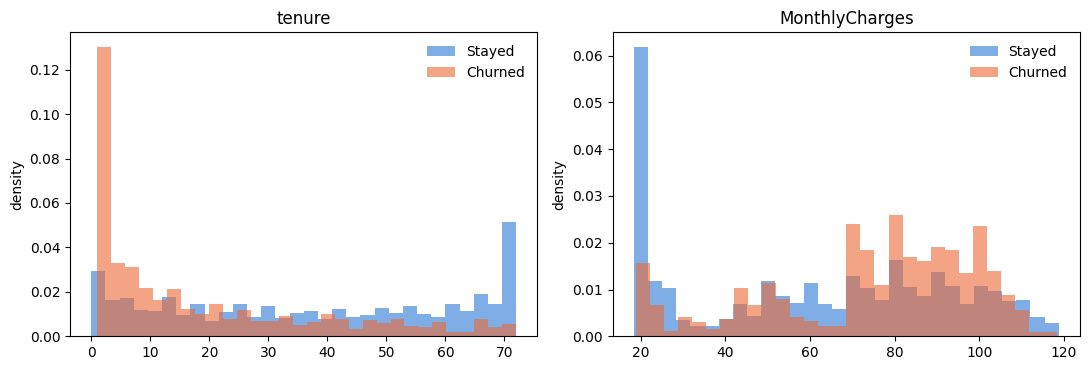

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges']):
    for label, colour in [(0, '#2a78d6'), (1, '#eb6834')]:
        ax.hist(train.loc[train.Churn == label, col], bins=30, alpha=0.6, color=colour,
                density=True, label='Churned' if label else 'Stayed')
    ax.set_title(col); ax.set_ylabel('density'); ax.legend(frameon=False)
plt.tight_layout()

In [5]:
bands = pd.cut(train.tenure, [-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])
(train.groupby(bands, observed=True)['Churn'].mean() * 100).round(1).rename('churn rate % by tenure band')

tenure
0-6      52.2
7-12     37.2
13-24    28.6
25-48    20.2
49-72     9.9
Name: churn rate % by tenure band, dtype: float64

## Correlated features

`TotalCharges` is close to `tenure x MonthlyCharges`, so the three numeric features carry overlapping information. That matters when reading SHAP values later: credit gets shared between correlated columns.

In [6]:
train[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.00,0.26,0.83,-0.35
MonthlyCharges,0.26,1.00,0.65,0.20
TotalCharges,0.83,0.65,1.00,-0.19
Churn,-0.35,0.20,-0.19,1.00


## Takeaways

- Churn concentrates in month-to-month contracts, the first year of tenure, electronic-check payers and fiber optic customers.
- Churners pay more per month on average.
- No missing values after cleaning; the only fix needed was `TotalCharges` for brand-new customers.
- These are associations, not causes. See `reports/eda_insights.md` for the exact numbers.